# Stage Four: Hypothesis Testing

**Hypothesis:** the most valuable cars at the key sales are now significantly younger than they were three years ago.

Three tests:

1. **Mann-Whitney U** on model year, then against now (no assumption about the shape of the distribution).
2. **Chi-square test of independence** between era and edition, with **Cramér's V** for the strength of the association.
3. **Bootstrap** confidence intervals for the shift in median model year and in the share of value from cars built since 1980.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")
THEN, NOW = "#7FA3BF", "#B8945A"
from scipy import stats

ERA_ORDER = ["Pre-war", "1946-69", "1970s", "1980s-90s", "2000s on"]
lots = pd.read_csv("../data/processed/top_lots_clean.csv")
then = lots[lots["when"] == "Then"]
now = lots[lots["when"] == "Now"]
rng = np.random.default_rng(42)

## Stage Four - Part One: Mann-Whitney U tests on model year

In [2]:
rows = []
for sale in ["All four sales"] + sorted(lots["week"].unique()):
    a = then if sale == "All four sales" else then[then["week"] == sale]
    b = now if sale == "All four sales" else now[now["week"] == sale]
    u, p = stats.mannwhitneyu(b["year"], a["year"], alternative="greater")
    rows.append({"sale": sale, "n_then": len(a), "n_now": len(b),
                 "median_then": a["year"].median(), "median_now": b["year"].median(),
                 "U": u, "p_value": p, "significant (5%)": "yes" if p < 0.05 else "no"})
mw = pd.DataFrame(rows)
mw.style.format({"p_value": "{:.2e}", "U": "{:.0f}", "median_then": "{:.0f}", "median_now": "{:.0f}"})

,sale,n_then,n_now,median_then,median_now,U,p_value,significant (5%)
0,All four sales,67,67,1967,1994,3022,2.73e-04,yes
1,Amelia,10,10,1970,1998,74,3.78e-02,yes
2,Arizona (RM Sotheby's),12,12,1970,1994,96,8.29e-02,no
3,Monterey,30,30,1964,1990,627,4.51e-03,yes
4,Paris (RM Sotheby's),15,15,1978,1997,120,3.94e-01,no


Pooled across the four sales, the 2026 top lots are significantly younger (p < 0.001). Monterey and Amelia are significant on their own. RM Arizona (p = 0.08) and RM Paris have only 12 and 15 lots each, so on their own they lack the power to show it, even though both medians moved forward by around 20 years.

## Stage Four - Part Two: Chi-square test of era against edition

In [3]:
table = pd.crosstab(lots["era"], lots["when"]).loc[ERA_ORDER, ["Then", "Now"]]
chi2, p, dof, expected = stats.chi2_contingency(table)
n = table.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
display(table)
print(f"chi-square = {chi2:.2f}, dof = {dof}, p = {p:.2e}, Cramer's V = {cramers_v:.3f}")
print(f"Smallest expected count: {expected.min():.1f}")

when,Then,Now
era,,
Pre-war,10,6
1946-69,31,15
1970s,5,2
1980s-90s,11,16
2000s on,10,28


chi-square = 17.30, dof = 4, p = 1.69e-03, Cramer's V = 0.359
Smallest expected count: 3.5


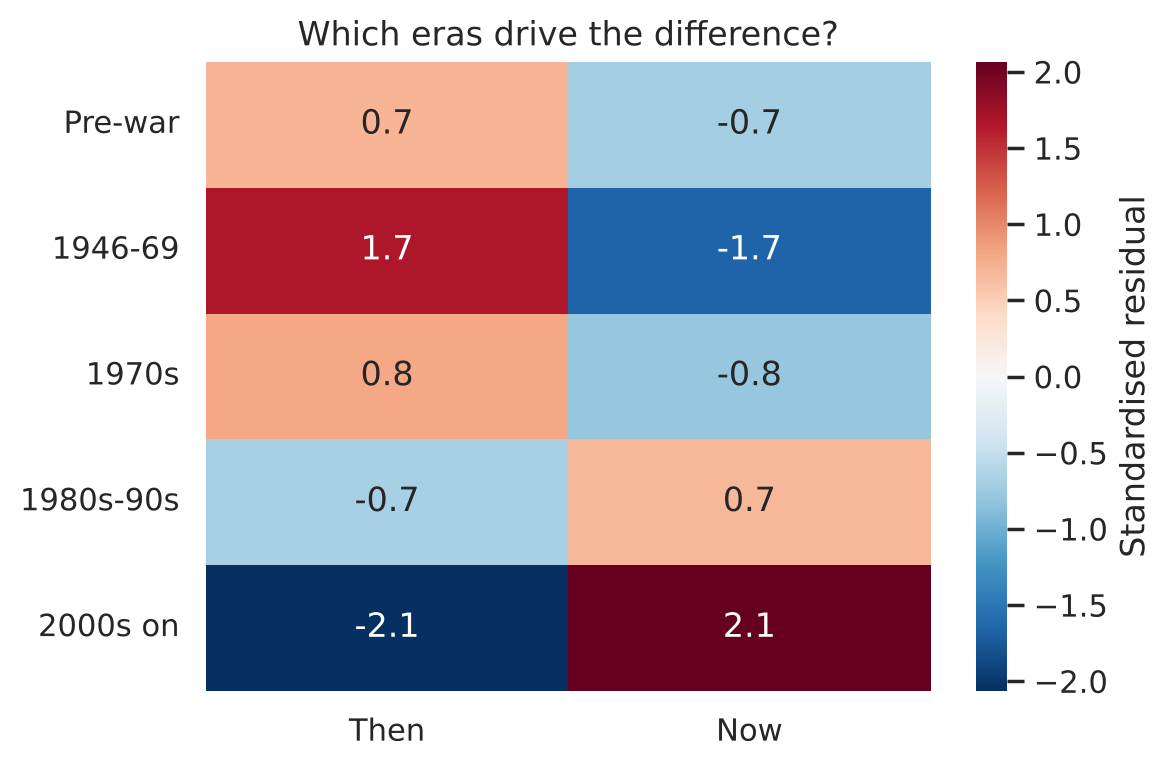

In [4]:
resid = (table - expected) / np.sqrt(expected)
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(resid, annot=True, fmt=".1f", cmap="RdBu_r", center=0, cbar_kws={"label": "Standardised residual"}, ax=ax)
ax.set_title("Which eras drive the difference?")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("../images/chi_square_residuals.png", dpi=150, bbox_inches="tight")
plt.show()

The association between era and edition is significant and of moderate strength. The residuals show where it comes from: fewer 1946 to 1969 cars than expected in 2026, and more cars built from 2000 on. The 1970s cell has a small expected count, so the p-value should be read with some caution; merging it into the 1946 to 1969 era gives the same conclusion (p < 0.001, smallest expected count 8).

## Stage Four - Part Three: Bootstrap confidence intervals

In [5]:
def share_1980_on(d):
    return d.loc[d["year"] >= 1980, "price_usd"].sum() / d["price_usd"].sum() * 100

B = 10_000
med_shift, share_shift = np.empty(B), np.empty(B)
for i in range(B):
    a = then.sample(len(then), replace=True, random_state=rng.integers(1e9))
    b = now.sample(len(now), replace=True, random_state=rng.integers(1e9))
    med_shift[i] = b["year"].median() - a["year"].median()
    share_shift[i] = share_1980_on(b) - share_1980_on(a)

obs_med = now["year"].median() - then["year"].median()
obs_share = share_1980_on(now) - share_1980_on(then)
ci = lambda x: np.percentile(x, [2.5, 97.5])
print(f"Median model year: {then['year'].median():.0f} -> {now['year'].median():.0f}, shift {obs_med:+.0f} years, 95% CI {ci(med_shift).round(0)}")
print(f"Value share from cars built 1980 on: {share_1980_on(then):.1f}% -> {share_1980_on(now):.1f}%, shift {obs_share:+.1f} points, 95% CI {ci(share_shift).round(1)}")

Median model year: 1967 -> 1994, shift +27 years, 95% CI [19. 36.]
Value share from cars built 1980 on: 27.0% -> 62.1%, shift +35.1 points, 95% CI [13.2 55.5]


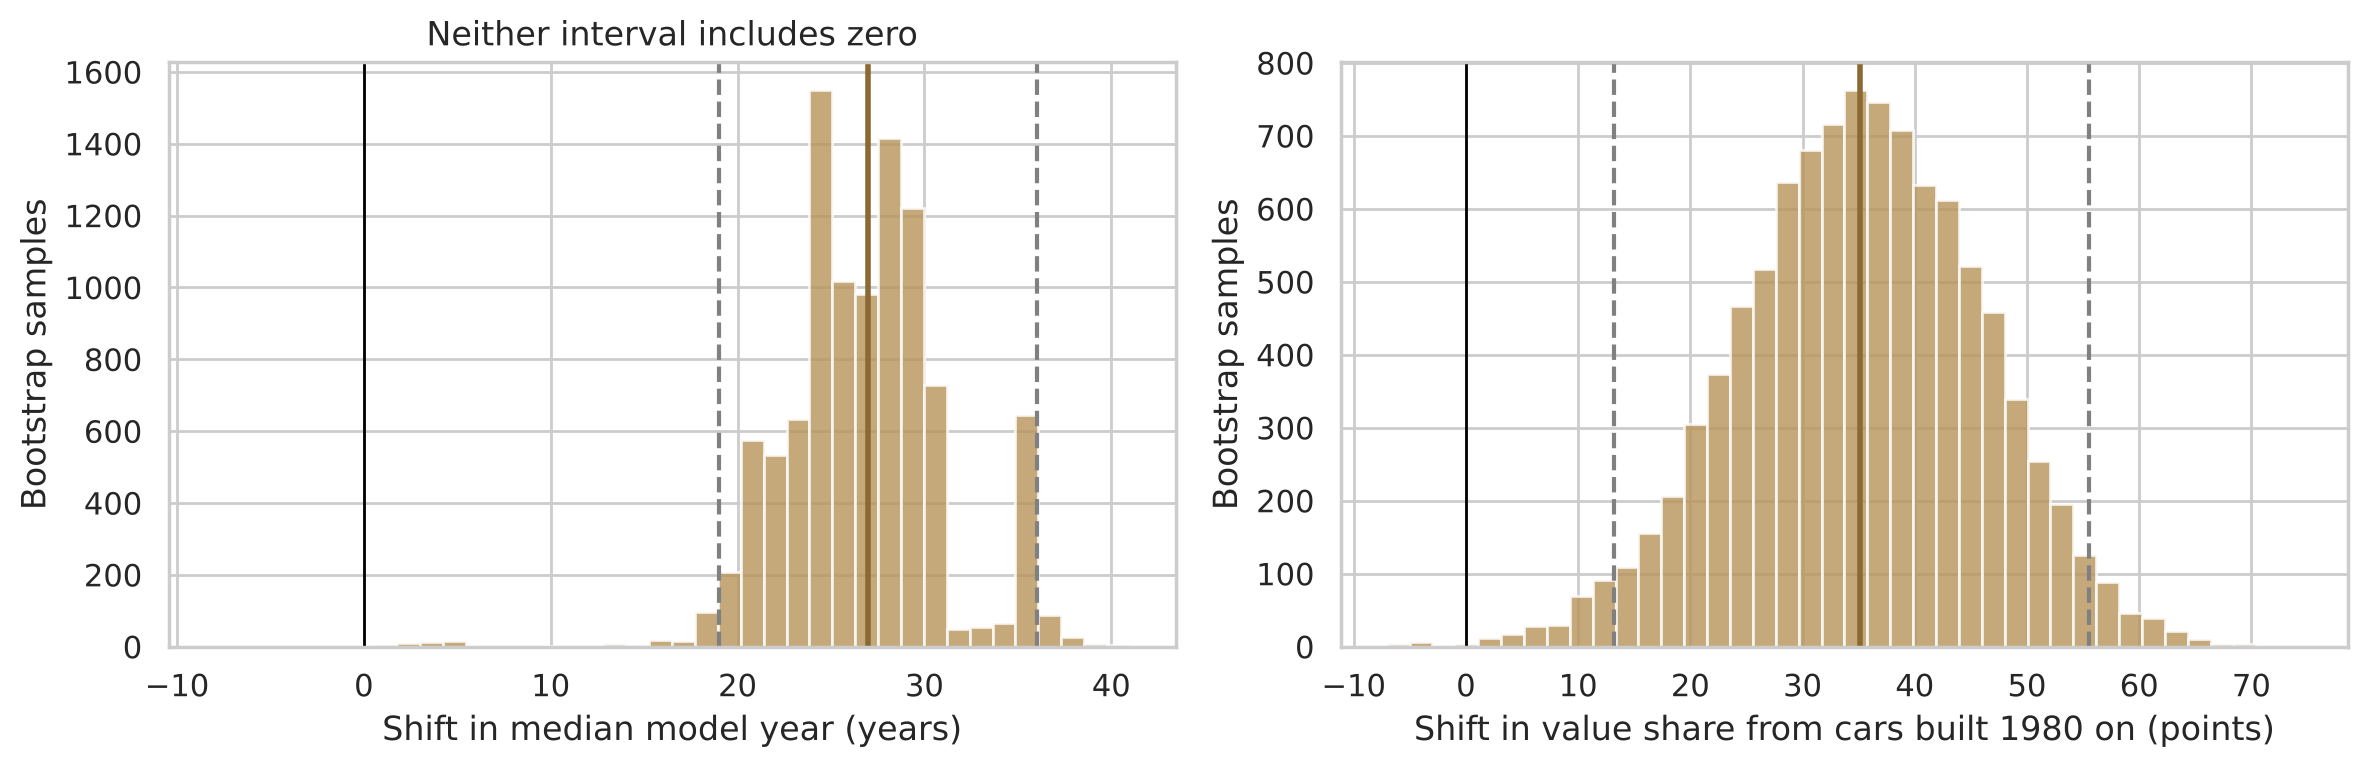

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, data, obs, label in [(axes[0], med_shift, obs_med, "Shift in median model year (years)"),
                             (axes[1], share_shift, obs_share, "Shift in value share from cars built 1980 on (points)")]:
    ax.hist(data, bins=40, color=NOW, alpha=0.8)
    lo, hi = ci(data)
    ax.axvline(0, color="black", lw=1)
    ax.axvline(lo, color="grey", ls="--")
    ax.axvline(hi, color="grey", ls="--")
    ax.axvline(obs, color="#8A6A32", lw=2)
    ax.set_xlabel(label)
    ax.set_ylabel("Bootstrap samples")
axes[0].set_title("Neither interval includes zero")
plt.tight_layout()
plt.savefig("../images/bootstrap.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusions

- The hypothesis holds for the top of the market. The median top lot moved from a 1967 car to a 1994 car, and cars built since 1980 went from about a quarter to nearly two-thirds of the value of the top lots. Neither 95% interval includes zero.
- The shift is clearest at Monterey and Amelia. RM Arizona moved furthest on value share but has too few lots to be significant on its own. Paris is the exception on value share, because its 2023 sale was led by a brand-new hypercar.
- The money grew too: Monterey nearly doubled, Paris and Amelia rose by around half, while Arizona and RM London were flat.

## Limitations

- **Top lots only.** This is the top of each sale, not every car sold, so it says nothing about the mid-market.
- **Hand-collected public data.** Sources count slightly differently (live results, post-sale deals, currency conversion).
- **Four sales, two years.** A single comparison cannot separate a lasting trend from the mix of cars that happened to be consigned.
- **Not compared:** Goodwood, as comparable 2026 results were not published, and Broad Arrow Zürich, which began in 2025.